<h2 align="center">Vehicle Damage Detection</h2>

## Project Overview

The objective of this project is to classify vehicle images into six categories based on their damage type and location:

1. Front Breakage
2. Front Crushed
3. Front Normal
4. Rear Breakage
5. Rear Crushed
6. Rear Normal

To achieve this, I experimented with different CNN architectures and transfer learning models to identify a suitable model for vehicle damage classification.

## Import Libraries

In [88]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt
import seaborn as sns

## Data Loading and Preprocessing

In [31]:
image_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [33]:
dataset_path = "./dataset"

dataset = datasets.ImageFolder(root=dataset_path, transform=image_transforms)
len(dataset)

2300

In [35]:
dataset.classes

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [36]:
num_classes = len(dataset.classes)
num_classes

6

### Train-Validation Split

In [37]:
train_size = int(0.75*len(dataset))
val_size = len(dataset) - train_size

train_size, val_size

(1725, 575)

In [38]:
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

### Creating DataLoaders

In [41]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=True)

### Inspecting a Sample Batch

In [42]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [51]:
labels[1]

tensor(0)

In [44]:
images[0].shape

torch.Size([3, 224, 224])

In [48]:
images[0].permute(1,2,0).shape

torch.Size([224, 224, 3])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


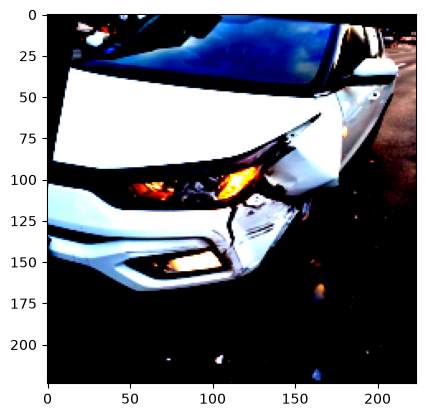

In [50]:
plt.imshow(images[1].permute(1,2,0))
plt.show()

## Model 1: Custom CNN

In [67]:
class CarClassifierCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),
            
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),
            nn.Flatten(),

            
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.network(x)
        return x

### Model Training

In [68]:
model = CarClassifierCNN(num_classes=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [69]:
def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_num, (images, labels) in enumerate(train_loader):

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            if (batch_num+1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():0.2f}")

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")

        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []
        with torch.no_grad():
            for images, labels in val_loader:
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.numpy())
                all_predictions.extend(predicted.numpy())

            print(f"*** Validation Accuracy: {100 * correct / total:.2f}% ***")
    end = time.time()
    print(f"Execution time: {end - start} seconds") 
            
    return all_labels, all_predictions

In [70]:
all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.79
Batch: 20, Epoch: 1, Loss: 1.72
Batch: 30, Epoch: 1, Loss: 1.64
Batch: 40, Epoch: 1, Loss: 1.58
Batch: 50, Epoch: 1, Loss: 1.37
Epoch [1/10], Avg Loss: 1.9187
*** Validation Accuracy: 39.13% ***
Batch: 10, Epoch: 2, Loss: 1.32
Batch: 20, Epoch: 2, Loss: 1.35
Batch: 30, Epoch: 2, Loss: 1.32
Batch: 40, Epoch: 2, Loss: 1.08
Batch: 50, Epoch: 2, Loss: 1.33
Epoch [2/10], Avg Loss: 1.2591
*** Validation Accuracy: 52.52% ***
Batch: 10, Epoch: 3, Loss: 1.33
Batch: 20, Epoch: 3, Loss: 1.07
Batch: 30, Epoch: 3, Loss: 1.28
Batch: 40, Epoch: 3, Loss: 0.86
Batch: 50, Epoch: 3, Loss: 1.16
Epoch [3/10], Avg Loss: 1.0904
*** Validation Accuracy: 54.61% ***
Batch: 10, Epoch: 4, Loss: 0.91
Batch: 20, Epoch: 4, Loss: 1.09
Batch: 30, Epoch: 4, Loss: 1.12
Batch: 40, Epoch: 4, Loss: 0.78
Batch: 50, Epoch: 4, Loss: 0.89
Epoch [4/10], Avg Loss: 0.9740
*** Validation Accuracy: 58.43% ***
Batch: 10, Epoch: 5, Loss: 0.79
Batch: 20, Epoch: 5, Loss: 0.73
Batch: 30, Epoch: 5, Loss: 1

## Model 2: CNN with Regularization

In [73]:
class CarClassifierCNNWithRegularization(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),
            
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),
            nn.Flatten(),

            
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.network(x)
        return x

### Model Training

In [75]:
model = CarClassifierCNNWithRegularization(num_classes=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

all_labels, all_predictions = train_model(model, criterion, optimizer,  epochs=10)

Batch: 10, Epoch: 1, Loss: 16.53
Batch: 20, Epoch: 1, Loss: 5.19
Batch: 30, Epoch: 1, Loss: 2.11
Batch: 40, Epoch: 1, Loss: 1.78
Batch: 50, Epoch: 1, Loss: 1.30
Epoch [1/10], Avg Loss: 7.3563
*** Validation Accuracy: 43.83% ***
Batch: 10, Epoch: 2, Loss: 1.40
Batch: 20, Epoch: 2, Loss: 1.45
Batch: 30, Epoch: 2, Loss: 1.33
Batch: 40, Epoch: 2, Loss: 1.42
Batch: 50, Epoch: 2, Loss: 1.50
Epoch [2/10], Avg Loss: 1.3817
*** Validation Accuracy: 50.78% ***
Batch: 10, Epoch: 3, Loss: 1.41
Batch: 20, Epoch: 3, Loss: 1.48
Batch: 30, Epoch: 3, Loss: 1.32
Batch: 40, Epoch: 3, Loss: 1.24
Batch: 50, Epoch: 3, Loss: 1.19
Epoch [3/10], Avg Loss: 1.2640
*** Validation Accuracy: 51.65% ***
Batch: 10, Epoch: 4, Loss: 1.33
Batch: 20, Epoch: 4, Loss: 1.18
Batch: 30, Epoch: 4, Loss: 1.28
Batch: 40, Epoch: 4, Loss: 1.24
Batch: 50, Epoch: 4, Loss: 1.26
Epoch [4/10], Avg Loss: 1.2087
*** Validation Accuracy: 49.91% ***
Batch: 10, Epoch: 5, Loss: 0.93
Batch: 20, Epoch: 5, Loss: 1.24
Batch: 30, Epoch: 5, Loss: 

## Model 3: Transfer Learning with EfficientNet-B0

In [76]:
class CarClassifierEfficientNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.efficientnet_b0(weights="DEFAULT")
        
        for param in self.model.parameters():
            param.requires_grad = False
        
        in_features = self.model.classifier[1].in_features

        self.model.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

### Model Training

In [78]:
model = CarClassifierEfficientNet(num_classes=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.67
Batch: 20, Epoch: 1, Loss: 1.59
Batch: 30, Epoch: 1, Loss: 1.53
Batch: 40, Epoch: 1, Loss: 1.33
Batch: 50, Epoch: 1, Loss: 1.27
Epoch [1/10], Avg Loss: 1.4908
*** Validation Accuracy: 57.57% ***
Batch: 10, Epoch: 2, Loss: 1.15
Batch: 20, Epoch: 2, Loss: 1.10
Batch: 30, Epoch: 2, Loss: 0.99
Batch: 40, Epoch: 2, Loss: 1.18
Batch: 50, Epoch: 2, Loss: 1.10
Epoch [2/10], Avg Loss: 1.1613
*** Validation Accuracy: 64.17% ***
Batch: 10, Epoch: 3, Loss: 0.96
Batch: 20, Epoch: 3, Loss: 0.98
Batch: 30, Epoch: 3, Loss: 1.07
Batch: 40, Epoch: 3, Loss: 1.00
Batch: 50, Epoch: 3, Loss: 1.15
Epoch [3/10], Avg Loss: 1.0381
*** Validation Accuracy: 64.35% ***
Batch: 10, Epoch: 4, Loss: 1.11
Batch: 20, Epoch: 4, Loss: 1.00
Batch: 30, Epoch: 4, Loss: 0.98
Batch: 40, Epoch: 4, Loss: 0.96
Batch: 50, Epoch: 4, Loss: 1.14
Epoch [4/10], Avg Loss: 0.9693
*** Validation Accuracy: 63.30% ***
Batch: 10, Epoch: 5, Loss: 1.04
Batch: 20, Epoch: 5, Loss: 0.89
Batch: 30, Epoch: 5, Loss: 0

## Model 4: Transfer Learning with ResNet50

In [79]:
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super().__init__()
        self.model = models.resnet50(weights="DEFAULT")

        for param in self.model.parameters():
            param.requires_grad = False

        for param in self.model.layer4.parameters():
            param.requires_grad = True

        self.model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

### Model Training

In [82]:
model = CarClassifierResNet(num_classes=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

labels, predictions = train_model(model,criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 0.98
Batch: 20, Epoch: 1, Loss: 0.87
Batch: 30, Epoch: 1, Loss: 0.57
Batch: 40, Epoch: 1, Loss: 0.69
Batch: 50, Epoch: 1, Loss: 0.54
Epoch [1/10], Avg Loss: 0.8519
*** Validation Accuracy: 76.70% ***
Batch: 10, Epoch: 2, Loss: 0.49
Batch: 20, Epoch: 2, Loss: 0.23
Batch: 30, Epoch: 2, Loss: 0.47
Batch: 40, Epoch: 2, Loss: 0.68
Batch: 50, Epoch: 2, Loss: 0.50
Epoch [2/10], Avg Loss: 0.4697
*** Validation Accuracy: 79.83% ***
Batch: 10, Epoch: 3, Loss: 0.34
Batch: 20, Epoch: 3, Loss: 0.33
Batch: 30, Epoch: 3, Loss: 0.31
Batch: 40, Epoch: 3, Loss: 0.45
Batch: 50, Epoch: 3, Loss: 0.56
Epoch [3/10], Avg Loss: 0.3557
*** Validation Accuracy: 77.39% ***
Batch: 10, Epoch: 4, Loss: 0.17
Batch: 20, Epoch: 4, Loss: 0.09
Batch: 30, Epoch: 4, Loss: 0.20
Batch: 40, Epoch: 4, Loss: 0.18
Batch: 50, Epoch: 4, Loss: 0.21
Epoch [4/10], Avg Loss: 0.2494
*** Validation Accuracy: 80.17% ***
Batch: 10, Epoch: 5, Loss: 0.13
Batch: 20, Epoch: 5, Loss: 0.32
Batch: 30, Epoch: 5, Loss: 0

### Hyperparameter Tuning

I performed Hyperparameter tuning in a separate notebook. The selected parameters for ResNet50 are:

- Dropout Rate: 0.2
- Learning Rate: 0.005

### Final Model Training

In [83]:
model = CarClassifierResNet(num_classes=num_classes, dropout_rate=0.2)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.005)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 2.22
Batch: 20, Epoch: 1, Loss: 0.81
Batch: 30, Epoch: 1, Loss: 0.50
Batch: 40, Epoch: 1, Loss: 1.07
Batch: 50, Epoch: 1, Loss: 0.80
Epoch [1/10], Avg Loss: 0.9101
*** Validation Accuracy: 72.00% ***
Batch: 10, Epoch: 2, Loss: 0.42
Batch: 20, Epoch: 2, Loss: 0.26
Batch: 30, Epoch: 2, Loss: 0.48
Batch: 40, Epoch: 2, Loss: 0.44
Batch: 50, Epoch: 2, Loss: 0.70
Epoch [2/10], Avg Loss: 0.5294
*** Validation Accuracy: 73.91% ***
Batch: 10, Epoch: 3, Loss: 0.47
Batch: 20, Epoch: 3, Loss: 0.52
Batch: 30, Epoch: 3, Loss: 0.32
Batch: 40, Epoch: 3, Loss: 0.32
Batch: 50, Epoch: 3, Loss: 0.55
Epoch [3/10], Avg Loss: 0.3960
*** Validation Accuracy: 76.17% ***
Batch: 10, Epoch: 4, Loss: 0.20
Batch: 20, Epoch: 4, Loss: 0.33
Batch: 30, Epoch: 4, Loss: 0.13
Batch: 40, Epoch: 4, Loss: 0.21
Batch: 50, Epoch: 4, Loss: 0.31
Epoch [4/10], Avg Loss: 0.2746
*** Validation Accuracy: 74.78% ***
Batch: 10, Epoch: 5, Loss: 0.38
Batch: 20, Epoch: 5, Loss: 0.08
Batch: 30, Epoch: 5, Loss: 0

## Model Evaluation

### Classification Report

In [99]:
from sklearn.metrics import classification_report

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.74      0.88      0.81       139
           1       0.79      0.50      0.61       101
           2       0.84      0.93      0.88       112
           3       0.77      0.86      0.81        63
           4       0.70      0.75      0.73        76
           5       0.90      0.76      0.83        84

    accuracy                           0.79       575
   macro avg       0.79      0.78      0.78       575
weighted avg       0.79      0.79      0.78       575



### Confusion Matrix

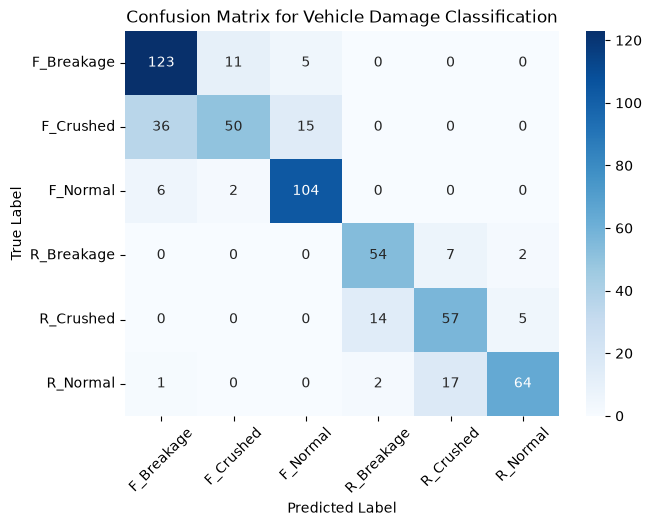

In [98]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

cm = confusion_matrix(labels, predictions, labels=np.arange(num_classes))

plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.xticks(rotation=45)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## Saving the Trained Model

In [101]:
torch.save(model.state_dict(), "saved_model.pth")